# Cathode analysis: a cation-disordered garnet

Use the pretrained ΔEdecomp model on a structure that is not in the training data: the disordered garnet
Li$_7$Pr$_3$(Mn$_{0.25}$Mo$_{0.75}$)$_2$O$_{12}$ (Mn and Mo share the octahedral sites, Li partly occupies its
sites). We predict:
1. its oxidation states;
2. the stable Li range (capacity);
3. the voltage profile over that range;
4. the energy density.

Inputs besides the structure:
- **Edecomp of the pristine garnet:** 13.6 meV/atom. This is a MACE estimate on the MP2020 GGA/GGA+U scale; for a
  new material it would come from a DFT or machine-learned energy and `thermo.edecomp_of`.
- **Competing phases of the Li–Mn–Mo–O–Pr system** for the voltages: MP2020-corrected GGA/GGA+U Materials Project
  entries, in `data/hull_docs_Li-Mn-Mo-O-Pr.json`. Without them, `thermo.docs_from_mp` fetches them with an MP API key.

In [1]:
%matplotlib inline
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

In [2]:
import json
from pymatgen.core import Structure
from ion_insertion_modeling import oxi_state_inference as oxi, insertion_stability as ins
from ion_insertion_modeling.model_building import load_pretrained

model = load_pretrained()  # ships with the package
garnet = Structure.from_file("data/disordered_Li7PrMoMnO.cif")
docs = json.loads(open("data/hull_docs_Li-Mn-Mo-O-Pr.json").read())
EDECOMP_INITIAL = 0.01364   # eV/atom (MACE estimate, MP2020 GGA/GGA+U scale)
FRAMEWORK = "Pr3Mo1.5Mn0.5O12"  # x counts Li per 12 O
print(model.features)

['has_polyanion', 'delta_p1_score', 'nval_d_redox_initial', 'delta_li_frac', 'site_cn_mean']


## 1. Oxidation states

ChemEnv runs once on the 208-site cell (about a minute) and is cached for every later call.

In [3]:
g = oxi.guess_from_structure(garnet)
print(g.states, f"score {g.score:.3f}")
print(g.environments)

{'Li': 1.0, 'Pr': 3.0, 'Mn': 2.0, 'Mo': 4.666666666666667, 'O': -2.0} score 0.537
[('Pr', 'C:8', 24.0), ('Mn', 'O:6', 4.0), ('Mo', 'O:6', 12.0)]


## 2. Stability over Li content

Every grid composition Li$_x$Pr$_3$Mo$_{1.5}$Mn$_{0.5}$O$_{12}$ is scored on the garnet's environments and
featurized; the model predicts ΔEdecomp from the pristine material.

In [4]:
grid = np.arange(3, 8.01, 0.25)
curve = ins.stability_curve(garnet, EDECOMP_INITIAL, model, x_grid=grid, framework=FRAMEWORK)
cap = curve.capacity()
print(f"stable range x = {cap.x_lo:g} to {cap.x_hi:g} (initial x = {curve.x_initial:g}); capacity {cap.capacity_mAh_g:.1f} mAh/g")
curve.states[["x", "formula", "p1_score", "edecomp_pred", "stable", "in_range"]].assign(
    edecomp_pred=lambda d: (1000 * d.edecomp_pred).round(1)).rename(columns={"edecomp_pred": "Ê (meV/atom)"})

stable range x = 4 to 8 (initial x = 7); capacity 127.4 mAh/g


,x,formula,p1_score,Ê (meV/atom),stable,in_range
0,3.00,Li6Pr6Mn1Mo3O24,0.155562,120.7,False,False
1,3.25,Li13Pr12Mn2Mo6O48,0.226755,87.2,False,False
2,3.50,Li7Pr6Mn1Mo3O24,0.330528,79.7,False,False
3,3.75,Li15Pr12Mn2Mo6O48,0.481793,85.6,False,False
4,4.00,Li8Pr6Mn1Mo3O24,0.702284,71.4,True,True
5,4.25,Li17Pr12Mn2Mo6O48,0.694329,62.2,True,True
6,4.50,Li9Pr6Mn1Mo3O24,0.686463,57.7,True,True
7,4.75,Li19Pr12Mn2Mo6O48,0.702127,61.7,True,True
8,5.00,Li10Pr6Mn1Mo3O24,0.718148,60.1,True,True
9,5.25,Li21Pr12Mn2Mo6O48,0.694308,53.9,True,True


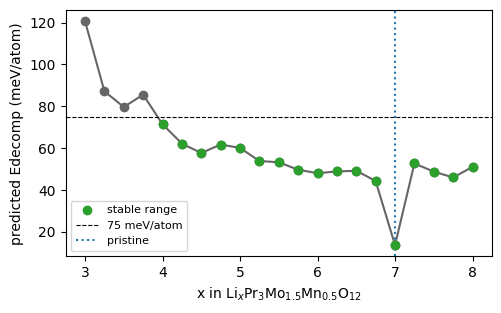

In [5]:
st = curve.states
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(st.x, 1000 * st.edecomp_pred, "o-", color="0.4")
ax.scatter(st.x[st.in_range], 1000 * st.edecomp_pred[st.in_range], color="tab:green", zorder=3, label="stable range")
ax.axhline(75, color="k", ls="--", lw=0.8, label="75 meV/atom")
ax.axvline(curve.x_initial, color="tab:blue", ls=":", label="pristine")
ax.set_xlabel("x in Li$_x$Pr$_3$Mo$_{1.5}$Mn$_{0.5}$O$_{12}$"); ax.set_ylabel("predicted Edecomp (meV/atom)"); ax.legend(fontsize=8)

## 3. Voltage profile

The predicted energy of each state is E(x) = E$_{hull}$(x) + Ê(x), with E$_{hull}$ from the competing phases.
G(x) = N(x)·E(x) − x·μ$_{Li}$ per framework formula unit. The voltage steps are V = −ΔG/Δx along the lower convex
envelope of G over the stable range.

   x_from  x_to      V
0    4.00  4.25  3.092
1    4.25  4.50  2.702
2    4.50  7.00  1.968
3    7.00  8.00  0.441


Text(0.5, 1.0, 'mean 1.70 V')

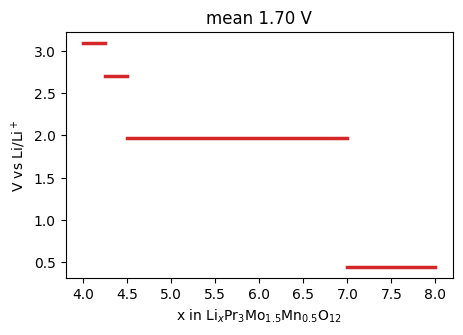

In [6]:
vp = ins.predict_voltage_profile(garnet, EDECOMP_INITIAL, model, docs=docs, x_grid=grid, framework=FRAMEWORK)
print(vp.steps.round(3))
fig, ax = plt.subplots(figsize=(5, 3.2))
for r in vp.steps.itertuples():
    ax.plot([r.x_from, r.x_to], [r.V, r.V], color="tab:red", lw=2.5)
ax.set_xlabel("x in Li$_x$Pr$_3$Mo$_{1.5}$Mn$_{0.5}$O$_{12}$"); ax.set_ylabel("V vs Li/Li$^+$")
ax.set_title(f"mean {vp.mean_voltage:.2f} V")

## 4. Energy density

In [7]:
e = ins.energy_density(vp)
print(f"{e.wh_per_kg:.0f} Wh/kg = {e.capacity_mAh_g:.1f} mAh/g × {e.mean_voltage:.2f} V (mass: framework + x_hi Li)")

217 Wh/kg = 127.4 mAh/g × 1.70 V (mass: framework + x_hi Li)


## 5. Environment assumption and screening many structures

The same capacity with every cation assumed octahedral (`environments="O:6"`, no ChemEnv), the shortcut for
compositions without a reliable structure:

In [8]:
cap_o6 = ins.predict_capacity(garnet, EDECOMP_INITIAL, model, x_grid=grid, framework=FRAMEWORK, environments="O:6")
print(f"ChemEnv environments: x = {cap.x_lo:g}-{cap.x_hi:g}, {cap.capacity_mAh_g:.1f} mAh/g")
print(f"all octahedral:       x = {cap_o6.x_lo:g}-{cap_o6.x_hi:g}, {cap_o6.capacity_mAh_g:.1f} mAh/g")

ChemEnv environments: x = 4-8, 127.4 mAh/g
all octahedral:       x = 4-8, 127.4 mAh/g


`predict_capacities` screens a list of structures (default grid: 41 contents from 0 to twice the pristine content);
a structure that fails is reported in the `error` column instead of stopping the run:

In [9]:
lfp = Structure.from_file("../tests/data/LiFePO4_mp-19017.cif")
ins.predict_capacities([lfp, lfp.copy().scale_lattice(lfp.volume * 1.02)], [-0.0082, -0.0082], model,
                       ids=["LiFePO4", "LiFePO4 (+2% volume)"])

,id,framework,x_initial,x_lo,x_hi,dx,capacity_mAh_g,error
0,LiFePO4,Fe1 P1 O4,1.0,0.0,1.0,1.0,169.890526,None
1,LiFePO4 (+2% volume),Fe1 P1 O4,1.0,0.0,1.0,1.0,169.890526,None


Caveats:
- The model was trained on ordered Materials Project electrodes. For a disordered structure, the environments are
  occupancy-weighted averages, and the predicted range is a screening estimate, not a DFT result.
- The voltages use predicted Edecomp values on a real hull, so their errors scale with the Edecomp MAE (about
  25 meV/atom per state).